# Module 6 — Le Transformer de zéro

> **Objectif** : comprendre chaque pièce du Transformer (Vaswani et al., 2017), l'architecture de BERT, GPT, LLaMA, ESM… et savoir **pourquoi** chaque pièce est là. On construit tout en NumPy pour voir les mécanismes (pourquoi diviser par $\sqrt{d}$, pourquoi des encodages de position, pourquoi LayerNorm et les connexions résiduelles), puis on écrit un **mini-GPT** complet en PyTorch qu'on entraîne et qu'on fait générer.

| | |
|---|---|
| **Durée estimée** | 4 h |
| **Prérequis** | Modules 0 à 5 (surtout l'attention du module 5) |
| **Librairies** | `numpy`, `matplotlib` ; `torch` pour les sections 10–12 |

**Plan**

1. Vue d'ensemble : un bloc répété $N$ fois
2. L'attention à produit scalaire mis à l'échelle (et pourquoi $\sqrt{d_k}$)
3. Les masques : causal et padding
4. L'attention multi-têtes
5. L'information de position : sinusoïdes, positions apprises, RoPE
6. Le réseau feed-forward
7. Connexions résiduelles et LayerNorm
8. Assembler un bloc ; un Transformer complet en NumPy
9. Coûts : paramètres, FLOPs, mémoire, cache KV
10. Un mini-GPT en PyTorch
11. Entraîner et générer
12. Les modules intégrés de PyTorch (et leurs pièges)
13. Récapitulatif et exercices

In [1]:
import numpy as np
import matplotlib.pyplot as plt

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.figsize": (7, 4), "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e0", "lines.linewidth": 2, "axes.titleweight": "bold",
    "legend.frameon": False, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
})
rng = np.random.default_rng(0)

def softmax(z, axis=-1):
    z = z - z.max(axis=axis, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=axis, keepdims=True)

## 1. Vue d'ensemble

### 💡 Intuition

Un Transformer transforme une séquence de vecteurs $(x_1,\dots,x_T)$ en une séquence de vecteurs de même forme, **plus riches en contexte**, en répétant $N$ fois le même type de bloc. Chaque bloc fait deux choses :

1. **Communiquer** (self-attention) : chaque token va chercher de l'information chez les autres tokens. « il » va regarder à quel nom il se rapporte ; « banque » regarde s'il y a « rivière » ou « crédit » autour.
2. **Réfléchir** (feed-forward) : chaque token traite, **seul**, l'information qu'il vient de rassembler, à travers un MLP.

Autour de ces deux opérations : des **connexions résiduelles** (on ajoute le résultat à l'entrée au lieu de la remplacer) et des **normalisations** (LayerNorm), qui rendent possible l'empilement de dizaines de blocs.

```
 tokens ──► Embedding + position ──► [ Bloc ] × N ──► LayerNorm ──► Linear ──► logits
                                       │
                         x ─┬─► LN ─► Self-Attention ─►(+)─┬─► LN ─► FFN ─►(+)─► x'
                            └──────────────────────────────┘└──────────────────┘
                                   connexion résiduelle         connexion résiduelle
```

### Trois familles

| Famille | Attention | Pré-entraînement | Exemples | Usage typique |
|---|---|---|---|---|
| **Encodeur seul** | bidirectionnelle (chaque token voit tout) | tokens masqués (MLM) | BERT, RoBERTa, CamemBERT, **ESM** | classification, étiquetage de tokens, embeddings |
| **Décodeur seul** | causale (chaque token ne voit que le passé) | token suivant (CLM) | GPT, LLaMA, Mistral, Claude | génération, chat |
| **Encodeur-décodeur** | bidirectionnelle + causale + croisée | débruitage | T5, BART, le Transformer original | traduction, résumé |

La différence entre BERT et GPT tient donc, pour l'essentiel, à **un masque** (section 3) et à **l'objectif d'entraînement** (module 7).

## 2. L'attention à produit scalaire mis à l'échelle

### 📐 Maths

Pour une séquence $X\in\mathbb R^{T\times d}$, on projette chaque token en requête, clé et valeur :
$$
Q = XW_Q,\quad K = XW_K,\quad V = XW_V,\qquad W_Q, W_K\in\mathbb R^{d\times d_k},\ W_V\in\mathbb R^{d\times d_v}
$$
$$
\boxed{\ \mathrm{Attention}(Q,K,V) = \mathrm{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V\ }
$$
- $QK^\top\in\mathbb R^{T\times T}$ : le score de chaque paire (token qui cherche $i$, token consulté $j$) ;
- softmax ligne par ligne : la ligne $i$ est une distribution sur les positions consultées ;
- multiplication par $V$ : chaque token reçoit une moyenne pondérée des valeurs.

Tout est **produit matriciel** : la séquence entière est traitée en parallèle.

### 📐 Pourquoi diviser par $\sqrt{d_k}$ ?

Si les composantes de $q$ et $k$ sont indépendantes, de moyenne 0 et de variance 1 :
$$
\mathbb E[q^\top k] = 0,\qquad \mathrm{Var}(q^\top k) = \sum_{i=1}^{d_k}\mathrm{Var}(q_ik_i) = d_k
$$
L'écart-type des scores croît comme $\sqrt{d_k}$. Avec $d_k = 64$, les scores ont un écart-type de 8 : la softmax devient quasiment un **argmax** (une seule position reçoit tout le poids), et son gradient s'annule (comme une sigmoïde saturée, module 0). Diviser par $\sqrt{d_k}$ ramène la variance à 1, quelle que soit la dimension.

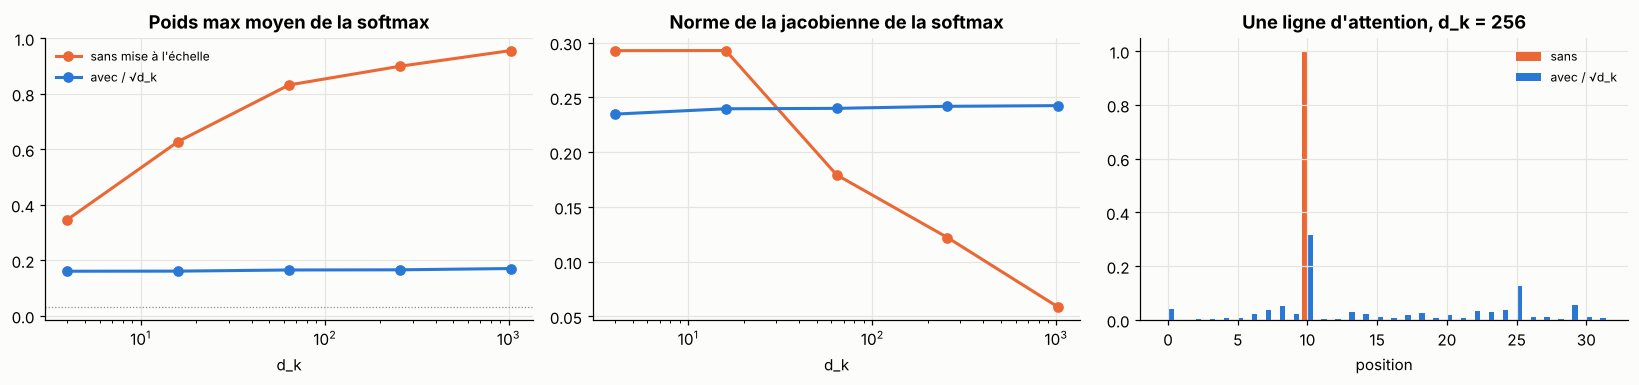

In [2]:
dims = [4, 16, 64, 256, 1024]
T_ = 32
stats = {"sans mise à l'échelle": [], "avec / √d_k": []}
grad_norms = {"sans mise à l'échelle": [], "avec / √d_k": []}
for d_k in dims:
    q = rng.normal(size=(500, d_k)); k = rng.normal(size=(500, T_, d_k))
    raw = np.einsum("bd,btd->bt", q, k)
    for name, scores in [("sans mise à l'échelle", raw), ("avec / √d_k", raw / np.sqrt(d_k))]:
        A = softmax(scores)
        stats[name].append(A.max(1).mean())
        # norm of the softmax Jacobian diag(a) - a a^T, averaged: how much gradient can flow back to the scores
        J = np.einsum("bi,ij->bij", A, np.eye(T_)) - np.einsum("bi,bj->bij", A, A)
        grad_norms[name].append(np.linalg.norm(J, axis=(1, 2)).mean())

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for (name, v), c in zip(stats.items(), [PALETTE[1], PALETTE[0]]):
    axes[0].semilogx(dims, v, "o-", color=c, label=name)
for (name, v), c in zip(grad_norms.items(), [PALETTE[1], PALETTE[0]]):
    axes[1].semilogx(dims, v, "o-", color=c, label=name)
axes[0].set_title("Poids max moyen de la softmax"); axes[0].set_xlabel("d_k"); axes[0].legend(fontsize=8)
axes[0].axhline(1 / T_, color="#8a8984", ls=":", lw=0.8)
axes[1].set_title("Norme de la jacobienne de la softmax"); axes[1].set_xlabel("d_k")
d_k = 256
q = rng.normal(size=d_k); k = rng.normal(size=(T_, d_k))
axes[2].bar(np.arange(T_) - 0.2, softmax(k @ q), width=0.4, color=PALETTE[1], label="sans")
axes[2].bar(np.arange(T_) + 0.2, softmax(k @ q / np.sqrt(d_k)), width=0.4, color=PALETTE[0], label="avec / √d_k")
axes[2].set_title(f"Une ligne d'attention, d_k = {d_k}"); axes[2].set_xlabel("position"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

Sans mise à l'échelle, dès $d_k \gtrsim 64$ l'attention est « one-hot » et presque aucun gradient ne passe : le modèle ne peut plus apprendre **où** regarder.

## 3. Les masques

On contrôle **qui peut regarder qui** en ajoutant $-\infty$ aux scores interdits avant la softmax (poids nul exactement) :

- **masque causal** (décodeur, GPT) : le token $i$ ne voit que $j\le i$. Indispensable pour un modèle de langue : sinon, pour prédire le token $t+1$, il lui suffirait de le lire !
- **masque de padding** : aucun token ne regarde les PAD (module 1).

$$
\mathrm{Attention} = \mathrm{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}} + M\right)V,\qquad M_{ij}=\begin{cases}0 & \text{autorisé}\\ -\infty & \text{interdit}\end{cases}
$$

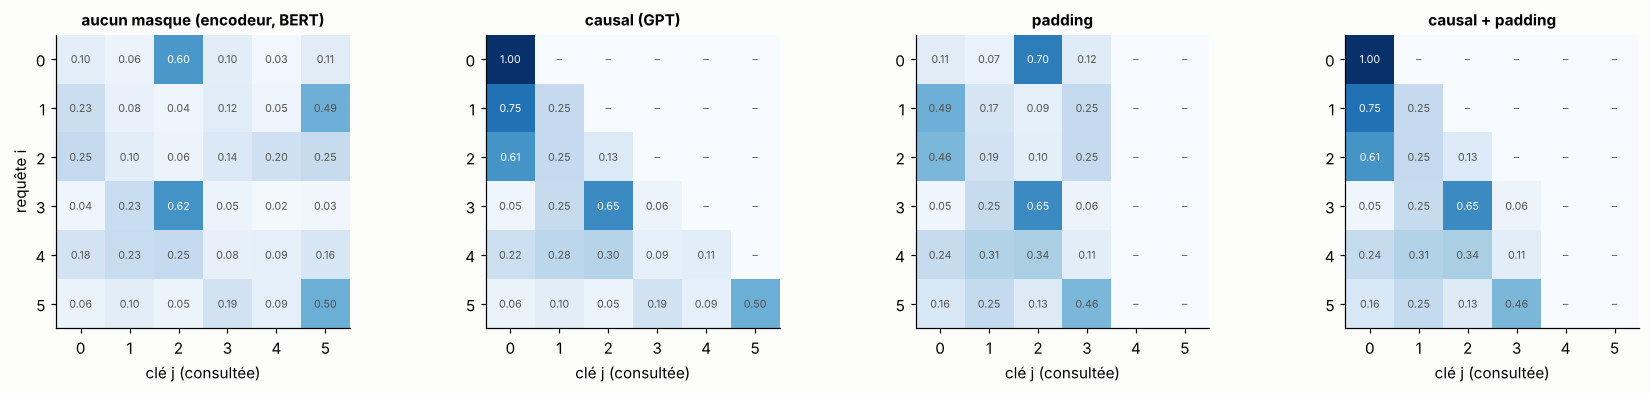

In [3]:
T_ = 6
lengths = 4                                                     # last 2 positions are PAD
causal = np.tril(np.ones((T_, T_), dtype=bool))                 # j <= i
padding = np.zeros((T_, T_), dtype=bool); padding[:, :lengths] = True   # can only look at real tokens
scores = rng.normal(size=(T_, T_))
masks = {"aucun masque (encodeur, BERT)": np.ones((T_, T_), bool), "causal (GPT)": causal,
         "padding": padding, "causal + padding": causal & padding}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, (name, m) in zip(axes, masks.items()):
    A = softmax(np.where(m, scores, -np.inf))
    A = np.nan_to_num(A)                                        # PAD query rows that see nothing
    ax.imshow(A, cmap="Blues", vmin=0, vmax=1)
    for (i, j), v in np.ndenumerate(A):
        ax.text(j, i, f"{v:.2f}" if m[i, j] else "–", ha="center", va="center", fontsize=7,
                color="white" if v > 0.55 else "#52514e")
    ax.set_title(name, fontsize=10); ax.set_xlabel("clé j (consultée)"); ax.grid(False)
axes[0].set_ylabel("requête i")
plt.tight_layout(); plt.show()

> ⚠️ **Piège numérique** : une ligne **entièrement** masquée (une requête PAD qui ne voit rien) donne $\mathrm{softmax}(-\infty,\dots,-\infty) = 0/0 =$ `NaN`, qui contamine tout le batch par rétropropagation. Solutions : utiliser une grande valeur négative finie (`-1e9`, ou `torch.finfo(dtype).min`), ou s'assurer que chaque ligne garde au moins une position autorisée (en masque causal, la diagonale est toujours permise).

## 4. L'attention multi-têtes

### 💡 Intuition

Une seule attention calcule **une** moyenne pondérée par token : elle ne peut suivre qu'un type de relation à la fois. Or un mot a simultanément besoin de son sujet (syntaxe), de l'antécédent d'un pronom (coréférence), du mot précédent (n-gramme local)… On fait donc tourner $h$ attentions **en parallèle**, chacune dans un sous-espace de dimension $d_k = d/h$, puis on recombine.

### 📐 Maths

$$
\mathrm{head}_i = \mathrm{Attention}(XW_Q^{(i)}, XW_K^{(i)}, XW_V^{(i)}),\qquad
\mathrm{MHA}(X) = [\mathrm{head}_1;\dots;\mathrm{head}_h]\,W_O
$$
avec $W_Q^{(i)}, W_K^{(i)}, W_V^{(i)}\in\mathbb R^{d\times d/h}$ et $W_O\in\mathbb R^{d\times d}$. **Coût en paramètres** : $4d^2$ (indépendant de $h$), même coût de calcul qu'une seule tête de dimension $d$.

**L'astuce d'implémentation** : on calcule $Q = XW_Q$ avec une seule matrice $d\times d$, puis on **découpe** la dernière dimension en $h$ têtes par un `reshape` : $(T, d)\to(T, h, d_k)\to(h, T, d_k)$ (module 1). Toutes les têtes sont alors calculées par un seul produit matriciel batché.

In [4]:
def mha_loop(X, W_Q, W_K, W_V, W_O, n_heads, mask=None):
    """Readable version: one head at a time."""
    T, d = X.shape
    dk = d // n_heads
    heads = []
    for h in range(n_heads):
        sl = slice(h * dk, (h + 1) * dk)
        Q, K, V = X @ W_Q[:, sl], X @ W_K[:, sl], X @ W_V[:, sl]
        S = Q @ K.T / np.sqrt(dk)
        if mask is not None:
            S = np.where(mask, S, -1e9)
        heads.append(softmax(S) @ V)
    return np.concatenate(heads, axis=-1) @ W_O


def mha(X, W_Q, W_K, W_V, W_O, n_heads, mask=None, return_attn=False):
    """Vectorized version with the reshape trick. X: (B, T, d)."""
    B, T, d = X.shape
    dk = d // n_heads
    split = lambda M: M.reshape(B, T, n_heads, dk).transpose(0, 2, 1, 3)    # (B, h, T, dk)
    Q, K, V = split(X @ W_Q), split(X @ W_K), split(X @ W_V)
    S = Q @ K.transpose(0, 1, 3, 2) / np.sqrt(dk)                          # (B, h, T, T)
    if mask is not None:
        S = np.where(mask, S, -1e9)
    A = softmax(S)
    out = (A @ V).transpose(0, 2, 1, 3).reshape(B, T, d)                     # merge heads back
    return (out @ W_O, A) if return_attn else out @ W_O


d, h, T_ = 16, 4, 7
W_Q, W_K, W_V, W_O = (rng.normal(size=(d, d)) / np.sqrt(d) for _ in range(4))
X = rng.normal(size=(2, T_, d))
causal = np.tril(np.ones((T_, T_), dtype=bool))
out_vec = mha(X, W_Q, W_K, W_V, W_O, h, causal)
out_loop = np.stack([mha_loop(X[b], W_Q, W_K, W_V, W_O, h, causal) for b in range(2)])
print("vectorized == loop:", np.allclose(out_vec, out_loop), "| output shape:", out_vec.shape)
print("parameters: 4 * d^2 =", 4 * d * d)

vectorized == loop: True | output shape: (2, 7, 16)
parameters: 4 * d^2 = 1024


## 5. L'information de position

### 💡 Le problème : l'attention ne connaît pas l'ordre

La self-attention est **équivariante par permutation** : si on mélange les tokens d'entrée, les sorties sont mélangées de la même façon, mais leurs valeurs sont inchangées. Sans information de position, « le chien mord l'homme » et « l'homme mord le chien » produisent **les mêmes vecteurs** (dans un autre ordre). Vérifions-le :

In [5]:
perm = rng.permutation(T_)
out = mha(X[:1], W_Q, W_K, W_V, W_O, h)                   # no mask
out_perm = mha(X[:1, perm], W_Q, W_K, W_V, W_O, h)
print("MHA(permuted X) == permuted MHA(X):", np.allclose(out_perm, out[:, perm]))

MHA(permuted X) == permuted MHA(X): True


Il faut donc **injecter la position**. Trois grandes approches.

### 5.1 Encodages sinusoïdaux (Transformer original)

On **ajoute** à l'embedding du token en position $p$ un vecteur fixe :
$$
PE_{p,2i} = \sin\!\left(\frac{p}{10000^{2i/d}}\right),\qquad PE_{p,2i+1} = \cos\!\left(\frac{p}{10000^{2i/d}}\right)
$$
Chaque paire de dimensions est une **horloge** tournant à sa propre fréquence, des aiguilles rapides (petits $i$) aux très lentes (grands $i$) : comme un compteur binaire, mais continu. Propriété clé : pour tout décalage $k$, $PE_{p+k}$ est une **rotation** (donc une fonction linéaire) de $PE_p$, ce qui permet au modèle de raisonner en positions **relatives**.

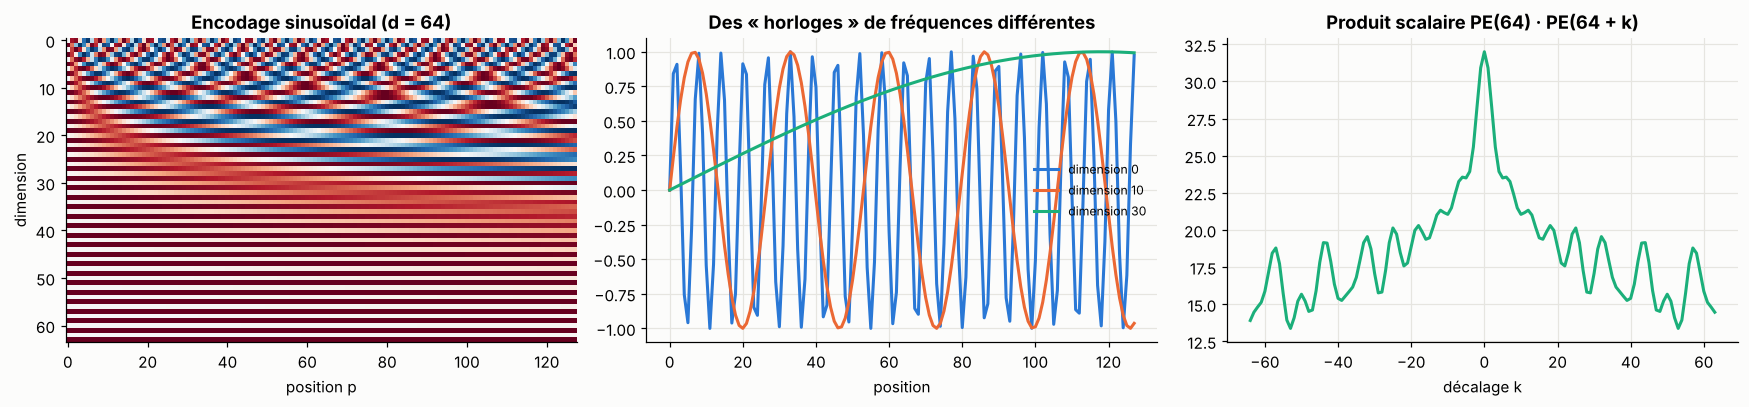

In [6]:
def sinusoidal_pe(T, d):
    pos = np.arange(T)[:, None]
    i = np.arange(d // 2)[None, :]
    angles = pos / 10000 ** (2 * i / d)
    pe = np.zeros((T, d))
    pe[:, 0::2], pe[:, 1::2] = np.sin(angles), np.cos(angles)
    return pe

pe = sinusoidal_pe(128, 64)
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
im = axes[0].imshow(pe.T, cmap="RdBu_r", aspect="auto", vmin=-1, vmax=1)
axes[0].set_xlabel("position p"); axes[0].set_ylabel("dimension"); axes[0].set_title("Encodage sinusoïdal (d = 64)"); axes[0].grid(False)
for dim, c in zip([0, 10, 30], PALETTE):
    axes[1].plot(pe[:, dim], color=c, label=f"dimension {dim}")
axes[1].set_title("Des « horloges » de fréquences différentes"); axes[1].set_xlabel("position"); axes[1].legend(fontsize=8)
sims = pe @ pe[64]
axes[2].plot(np.arange(128) - 64, sims, color=PALETTE[2])
axes[2].set_title("Produit scalaire PE(64) · PE(64 + k)"); axes[2].set_xlabel("décalage k")
plt.tight_layout(); plt.show()

La dernière figure montre que la similarité entre deux encodages ne dépend (presque) que de leur **distance** et décroît avec elle : les positions proches se ressemblent.

### 5.2 Positions apprises (BERT, GPT-2)

Une simple table `nn.Embedding(T_max, d)` apprise comme les embeddings de mots. Simple et efficace, mais **aucune généralisation** au-delà de `T_max` (la position 513 n'a jamais été vue par un modèle entraîné sur 512).

### 5.3 RoPE : les embeddings rotatifs (LLaMA, Mistral, ESM-2…)

Au lieu d'ajouter un vecteur à l'entrée, on **fait tourner** les requêtes et les clés, juste avant le produit scalaire, d'un angle proportionnel à leur position. Pour chaque paire de dimensions $(2i, 2i+1)$, d'angle de base $\theta_i = 10000^{-2i/d}$ :
$$
R_p\begin{pmatrix}x_{2i}\\x_{2i+1}\end{pmatrix} = \begin{pmatrix}\cos p\theta_i & -\sin p\theta_i\\ \sin p\theta_i & \cos p\theta_i\end{pmatrix}\begin{pmatrix}x_{2i}\\x_{2i+1}\end{pmatrix}
$$
Comme $R_m^\top R_n = R_{n-m}$ (deux rotations se composent) :
$$
(R_m q)^\top (R_n k) = q^\top R_{n-m}\,k
$$
**Le score ne dépend que de la position relative $n-m$**, exactement, et sans paramètre supplémentaire. C'est l'encodage dominant dans les grands modèles actuels.

In [7]:
def rope(x, positions, base=10000.0):
    """x: (T, d) with d even. Rotate each pair (2i, 2i+1) by angle pos * base^(-2i/d)."""
    T, d = x.shape
    theta = base ** (-np.arange(0, d, 2) / d)                  # (d/2,)
    ang = positions[:, None] * theta[None, :]                 # (T, d/2)
    cos, sin = np.cos(ang), np.sin(ang)
    x1, x2 = x[:, 0::2], x[:, 1::2]
    out = np.empty_like(x)
    out[:, 0::2] = x1 * cos - x2 * sin
    out[:, 1::2] = x1 * sin + x2 * cos
    return out

d_rope = 32
q = rng.normal(size=(1, d_rope)); k = rng.normal(size=(1, d_rope))
def rope_score(m, n):
    return (rope(q, np.array([m])) @ rope(k, np.array([n])).T).item()
print("score(m=3,  n=7)  =", round(rope_score(3, 7), 6))
print("score(m=103,n=107)=", round(rope_score(103, 107), 6), " <- same relative offset (4), same score")
print("score(m=3,  n=9)  =", round(rope_score(3, 9), 6), " <- different offset, different score")
print("norm preserved:", np.allclose(np.linalg.norm(rope(q, np.array([50]))), np.linalg.norm(q)))

score(m=3,  n=7)  = 5.562682
score(m=103,n=107)= 5.562682  <- same relative offset (4), same score
score(m=3,  n=9)  = 1.797254  <- different offset, different score
norm preserved: True


## 6. Le réseau feed-forward

Après la communication entre tokens, chaque position passe **indépendamment** dans le même MLP à deux couches :
$$
\mathrm{FFN}(x) = W_2\,\phi(W_1x + b_1) + b_2,\qquad W_1\in\mathbb R^{4d\times d},\ W_2\in\mathbb R^{d\times 4d}
$$
avec $\phi$ = GELU (GPT, BERT). La couche cachée est typiquement **4 fois plus large** : $8d^2$ paramètres, soit **deux tiers** des paramètres d'un bloc.

**Variante SwiGLU** (LLaMA, PaLM) : $\mathrm{FFN}(x) = W_2\big(\mathrm{SiLU}(W_1x)\odot W_3x\big)$, une porte multiplicative qui améliore un peu la qualité à paramètres égaux (on réduit alors la largeur à $\frac{8}{3}d$ pour garder le même budget).

**Interprétation** (Geva et al., 2021) : les lignes de $W_1$ agissent comme des **clés** qui détectent des motifs dans le vecteur du token, et les colonnes de $W_2$ comme les **valeurs** associées qui sont ajoutées au flux résiduel. Une grande partie des « connaissances factuelles » d'un modèle de langue semble stockée dans ces couches.

## 7. Connexions résiduelles et LayerNorm

### 7.1 Connexions résiduelles

Au lieu de $x_{l+1} = f(x_l)$, on calcule $x_{l+1} = x_l + f(x_l)$. Deux bénéfices :
- **gradient** : $\frac{\partial x_{l+1}}{\partial x_l} = I + \frac{\partial f}{\partial x_l}$. Le terme $I$ crée une **autoroute** : le gradient atteint les premières couches sans être multiplié par une chaîne de jacobiennes (même idée que la cellule du LSTM, module 4) ;
- **représentation** : chaque bloc **ajoute** une correction à un « flux résiduel » partagé (*residual stream*), au lieu de tout réécrire. On peut lire le Transformer comme une suite de blocs qui lisent et écrivent dans ce flux.

### 7.2 LayerNorm

Pour un vecteur $x\in\mathbb R^d$ (un token) :
$$
\mathrm{LN}(x) = \gamma\odot\frac{x-\mu}{\sqrt{\sigma^2+\epsilon}} + \beta,\qquad \mu = \frac1d\sum_i x_i,\quad \sigma^2 = \frac1d\sum_i(x_i-\mu)^2
$$
avec $\gamma,\beta\in\mathbb R^d$ appris. La normalisation se fait **sur les features de chaque token**, indépendamment des autres tokens et des autres exemples.

**Pourquoi pas BatchNorm** (qui normalise chaque feature sur le batch) ? En NLP, les séquences ont des longueurs variables et des PAD, les batchs sont parfois petits, et à l'inférence on génère un token à la fois : les statistiques de batch sont instables ou n'ont pas de sens. LayerNorm n'a aucune dépendance au batch. (Variante moderne : **RMSNorm**, $x/\sqrt{\frac1d\sum x_i^2}\odot\gamma$, sans centrage ni $\beta$, utilisée par LLaMA.)

### 7.3 Pre-LN vs Post-LN

- **Post-LN** (original) : $x_{l+1} = \mathrm{LN}(x_l + f(x_l))$. La normalisation est **sur** l'autoroute résiduelle : instable pour les modèles profonds, exige un warmup soigneux.
- **Pre-LN** (GPT-2 et quasiment tous les modèles récents) : $x_{l+1} = x_l + f(\mathrm{LN}(x_l))$. L'autoroute reste intacte, l'entraînement est bien plus stable. Il faut alors un LayerNorm final avant la tête de sortie.

In [8]:
def layer_norm(x, gamma=None, beta=None, eps=1e-5):
    mu = x.mean(-1, keepdims=True)
    var = x.var(-1, keepdims=True)
    y = (x - mu) / np.sqrt(var + eps)
    return y * (gamma if gamma is not None else 1) + (beta if beta is not None else 0)

x = rng.normal(5, 3, size=(2, 4, 8))                # (B, T, d), shifted and scaled
y = layer_norm(x)
print("per-token mean after LN:", y.mean(-1).round(6)[0], "| per-token std:", y.std(-1).round(3)[0])

per-token mean after LN: [-0. -0. -0. -0.] | per-token std: [1. 1. 1. 1.]


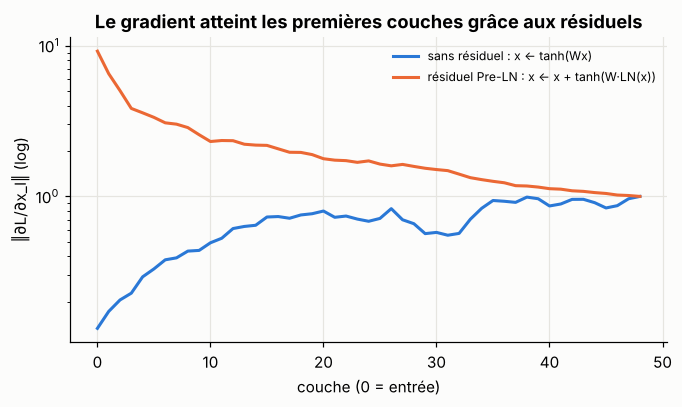

In [9]:
# Gradient flow through 48 random layers: plain stack vs residual stack (Pre-LN style)
def grad_norms_through_depth(residual, depth=48, d=64, seed=0):
    r = np.random.default_rng(seed)
    Ws = [r.normal(0, 1 / np.sqrt(d), (d, d)) for _ in range(depth)]
    x = r.normal(size=d)
    xs, pre = [x], []
    for W in Ws:                                       # forward
        u = layer_norm(x) if residual else x
        z = W @ u; pre.append((u, z))
        f = np.tanh(z)
        x = x + f if residual else f
        xs.append(x)
    g = np.ones(d) / np.sqrt(d)                        # dL/dx_L
    norms = [np.linalg.norm(g)]
    for (u, z), W, x_in in zip(reversed(pre), reversed(Ws), reversed(xs[:-1])):   # backward
        g_f = W.T @ (g * (1 - np.tanh(z) ** 2))        # through tanh and W
        if residual:                                    # through LayerNorm (no affine), then add identity path
            mu, sd = x_in.mean(), np.sqrt(x_in.var() + 1e-5)
            xh = (x_in - mu) / sd
            g_ln = (g_f - g_f.mean() - xh * (g_f * xh).mean()) / sd
            g = g + g_ln
        else:
            g = g_f
        norms.append(np.linalg.norm(g))
    return np.array(norms[::-1])

plt.figure(figsize=(7, 3.6))
plt.semilogy(grad_norms_through_depth(False), label="sans résiduel : x ← tanh(Wx)")
plt.semilogy(grad_norms_through_depth(True), label="résiduel Pre-LN : x ← x + tanh(W·LN(x))")
plt.xlabel("couche (0 = entrée)"); plt.ylabel("‖∂L/∂x_l‖ (log)"); plt.legend(fontsize=8)
plt.title("Le gradient atteint les premières couches grâce aux résiduels")
plt.show()

Sans résiduels, la norme du gradient est divisée par ~8 en 48 couches (et bien plus avec une initialisation moins soignée, module 0). Avec résiduels, elle ne s'éteint jamais : elle **croît** même doucement vers l'entrée, car chaque bloc ajoute sa contribution au chemin identité. Cette croissance est l'une des raisons pour lesquelles GPT-2 réduit l'initialisation des projections résiduelles d'un facteur $1/\sqrt{2L}$ (section 10).

## 8. Assembler un bloc ; un Transformer complet en NumPy

Un bloc **Pre-LN** de type GPT :
$$
\begin{aligned}
x &\leftarrow x + \mathrm{MHA}(\mathrm{LN}_1(x))\\
x &\leftarrow x + \mathrm{FFN}(\mathrm{LN}_2(x))
\end{aligned}
$$
Et le modèle complet : embeddings de tokens + positions → $N$ blocs → LN final → projection sur le vocabulaire.

In [10]:
def gelu(x):
    return 0.5 * x * (1 + np.tanh(np.sqrt(2 / np.pi) * (x + 0.044715 * x**3)))   # GPT-2's approximation


def init_gpt(V, T_max, d, n_layers, n_heads, seed=0):
    r = np.random.default_rng(seed)
    n = lambda *shape: r.normal(0, 0.02, shape)
    params = {"tok_emb": n(V, d), "pos_emb": n(T_max, d), "n_heads": n_heads, "blocks": []}
    for _ in range(n_layers):
        params["blocks"].append({
            "W_Q": n(d, d), "W_K": n(d, d), "W_V": n(d, d), "W_O": n(d, d),
            "W_1": n(d, 4 * d), "b_1": np.zeros(4 * d), "W_2": n(4 * d, d), "b_2": np.zeros(d),
        })
    return params


def gpt_forward(params, idx, return_attn=False):
    B, T = idx.shape
    x = params["tok_emb"][idx] + params["pos_emb"][:T]             # (B, T, d)
    mask = np.tril(np.ones((T, T), dtype=bool))                    # causal
    attns = []
    for blk in params["blocks"]:
        a, A = mha(layer_norm(x), blk["W_Q"], blk["W_K"], blk["W_V"], blk["W_O"], params["n_heads"], mask, return_attn=True)
        x = x + a                                                  # communicate
        x = x + gelu(layer_norm(x) @ blk["W_1"] + blk["b_1"]) @ blk["W_2"] + blk["b_2"]   # think
        attns.append(A)
    logits = layer_norm(x) @ params["tok_emb"].T                   # weight tying: reuse the embedding matrix
    return (logits, attns) if return_attn else logits


params = init_gpt(V=50, T_max=32, d=32, n_layers=2, n_heads=4)
idx = rng.integers(0, 50, (2, 10))
logits = gpt_forward(params, idx)
print("logits:", logits.shape, "| initial loss ≈", round(-np.log(softmax(logits)[0, np.arange(9), idx[0, 1:]]).mean(), 3),
      "vs log V =", round(np.log(50), 3))

logits: (2, 10, 50) | initial loss ≈ 3.855 vs log V = 3.912


**Le test de causalité** : dans un modèle de langue correct, la sortie en position $t$ ne doit **pas** dépendre des tokens après $t$. Si ce test échoue, le modèle « triche » à l'entraînement (perte très basse) et génère n'importe quoi. C'est le bug n°1 des implémentations maison :

In [11]:
idx2 = idx.copy()
idx2[:, 6:] = rng.integers(0, 50, (2, 4))          # change the "future" tokens (positions 6..9)
l1, l2 = gpt_forward(params, idx), gpt_forward(params, idx2)
print("positions 0-5 unchanged:", np.allclose(l1[:, :6], l2[:, :6]))
print("positions 6-9 changed  :", not np.allclose(l1[:, 6:], l2[:, 6:]))

positions 0-5 unchanged: True
positions 6-9 changed  : True


## 9. Coûts : paramètres, FLOPs, mémoire, cache KV

### 📐 Paramètres

Par bloc : attention $4d^2$ + FFN $8d^2$ (+ biais et LayerNorm, négligeables) $\approx 12d^2$. Total :
$$
N_{\text{params}}\approx 12\,L\,d^2 + V d\ (+\,T_{\max}d)
$$

In [12]:
def n_params(L, d, V, T_max, tied=True):
    per_block = 12 * d * d + 13 * d                    # weights + biases + 2 LayerNorms (approx.)
    return L * per_block + V * d + T_max * d + (0 if tied else V * d) + 2 * d

for name, L, d, V, T in [("GPT-2 small", 12, 768, 50257, 1024), ("GPT-2 medium", 24, 1024, 50257, 1024),
                         ("BERT-base", 12, 768, 30522, 512), ("ESM-2 650M", 33, 1280, 33, 1026)]:
    print(f"{name:13s}: ≈ {n_params(L, d, V, T) / 1e6:6.0f} M parameters")

GPT-2 small  : ≈    124 M parameters
GPT-2 medium : ≈    355 M parameters
BERT-base    : ≈    109 M parameters
ESM-2 650M   : ≈    651 M parameters


(Valeurs publiées : GPT-2 small 124 M, medium 355 M, BERT-base 110 M, ESM-2 650 M. La formule $12Ld^2$ suffit pour une estimation à quelques % près.)

### 📐 Calcul et mémoire

Pour une séquence de $T$ tokens, par couche :
- projections et FFN : $\approx 24\,T\,d^2$ FLOPs (linéaire en $T$) ;
- scores $QK^\top$ et produit par $V$ : $\approx 4\,T^2 d$ FLOPs, et une matrice $T\times T$ par tête à stocker (**quadratique** en $T$).

Pour les séquences courtes, le FFN domine ; au-delà de $T\approx 6d$, c'est l'attention. C'est la raison d'être de **FlashAttention** (même calcul, sans jamais matérialiser la matrice $T\times T$ en mémoire GPU) et des nombreuses attentions « efficaces ».

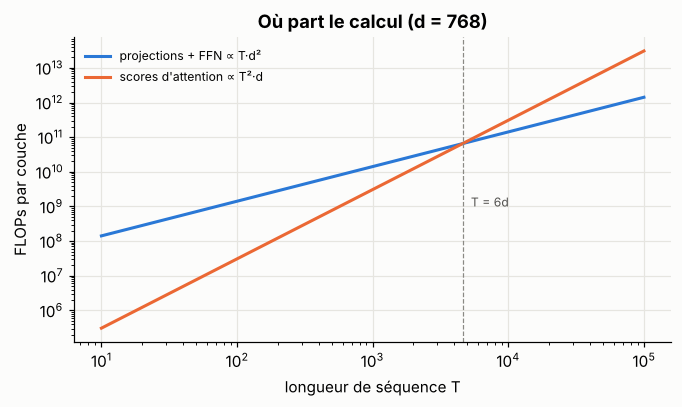

In [13]:
d = 768
Ts = np.logspace(1, 5, 50)
ffn_proj = 24 * Ts * d**2
attn = 4 * Ts**2 * d
plt.figure(figsize=(7, 3.6))
plt.loglog(Ts, ffn_proj, label="projections + FFN ∝ T·d²")
plt.loglog(Ts, attn, label="scores d'attention ∝ T²·d")
plt.axvline(6 * d, color="#8a8984", ls="--", lw=0.8); plt.text(6 * d * 1.15, 1e9, "T = 6d", fontsize=8, color="#52514e")
plt.xlabel("longueur de séquence T"); plt.ylabel("FLOPs par couche"); plt.title(f"Où part le calcul (d = {d})"); plt.legend(fontsize=8)
plt.show()

### Le cache KV (génération)

En génération autorégressive, à chaque nouveau token, les clés et valeurs des tokens **précédents** ne changent pas (masque causal !). On les garde en mémoire et on ne calcule que $q, k, v$ du nouveau token : le coût d'un pas passe de $O(T^2)$ à $O(T)$. C'est le **cache KV**, présent dans tous les moteurs d'inférence, et la raison pour laquelle la longueur de contexte coûte surtout de la **mémoire** en inférence.

## 10. Un mini-GPT en PyTorch

Même architecture que la version NumPy, à la manière de *nanoGPT* (A. Karpathy) : chaque ligne correspond à une équation de ce module.

In [ ]:
import math
import re

import torch
import torch.nn as nn
import torch.nn.functional as F
from dataclasses import dataclass


@dataclass
class GPTConfig:
    vocab_size: int
    block_size: int = 128        # maximum context length T_max
    n_layer: int = 4
    n_head: int = 4
    n_embd: int = 128
    dropout: float = 0.1


class CausalSelfAttention(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        assert cfg.n_embd % cfg.n_head == 0
        self.qkv = nn.Linear(cfg.n_embd, 3 * cfg.n_embd)        # W_Q, W_K, W_V fused in one matmul
        self.proj = nn.Linear(cfg.n_embd, cfg.n_embd)           # W_O
        self.n_head, self.dropout = cfg.n_head, cfg.dropout
        self.resid_drop = nn.Dropout(cfg.dropout)

    def forward(self, x, use_flash=True):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=2)
        q, k, v = (t.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) for t in (q, k, v))  # (B, h, T, dk)
        if use_flash:   # fused kernel (FlashAttention when available): same math, much less memory
            y = F.scaled_dot_product_attention(q, k, v, is_causal=True, dropout_p=self.dropout if self.training else 0.0)
        else:           # explicit version, identical to the equations
            att = (q @ k.transpose(-2, -1)) / math.sqrt(k.size(-1))
            causal = torch.tril(torch.ones(T, T, dtype=torch.bool, device=x.device))
            att = att.masked_fill(~causal, float("-inf")).softmax(dim=-1)
            att = F.dropout(att, self.dropout, self.training)
            y = att @ v
        y = y.transpose(1, 2).contiguous().view(B, T, C)        # merge heads
        return self.resid_drop(self.proj(y))


class MLP(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.fc = nn.Linear(cfg.n_embd, 4 * cfg.n_embd)
        self.proj = nn.Linear(4 * cfg.n_embd, cfg.n_embd)
        self.drop = nn.Dropout(cfg.dropout)

    def forward(self, x):
        return self.drop(self.proj(F.gelu(self.fc(x))))


class Block(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.ln1, self.attn = nn.LayerNorm(cfg.n_embd), CausalSelfAttention(cfg)
        self.ln2, self.mlp = nn.LayerNorm(cfg.n_embd), MLP(cfg)

    def forward(self, x):
        x = x + self.attn(self.ln1(x))       # communicate (Pre-LN)
        x = x + self.mlp(self.ln2(x))        # think
        return x


class GPT(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.n_embd)
        self.pos_emb = nn.Embedding(cfg.block_size, cfg.n_embd)
        self.drop = nn.Dropout(cfg.dropout)
        self.blocks = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layer)])
        self.ln_f = nn.LayerNorm(cfg.n_embd)
        self.head = nn.Linear(cfg.n_embd, cfg.vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight                  # weight tying
        self.apply(self._init_weights)
        for name, p in self.named_parameters():                 # GPT-2: scale residual projections by 1/sqrt(2L)
            if name.endswith("proj.weight"):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * cfg.n_layer))

    def _init_weights(self, m):
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, 0.0, 0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, 0.0, 0.02)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        assert T <= self.cfg.block_size, "sequence longer than the context window"
        pos = torch.arange(T, device=idx.device)
        x = self.drop(self.tok_emb(idx) + self.pos_emb(pos))
        for blk in self.blocks:
            x = blk(x)
        logits = self.head(self.ln_f(x))                        # (B, T, V)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.cfg.block_size:]               # crop to the context window
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / temperature
            if top_k is not None:
                v, _ = torch.topk(logits, top_k)
                logits[logits < v[:, [-1]]] = float("-inf")
            idx = torch.cat([idx, torch.multinomial(F.softmax(logits, dim=-1), 1)], dim=1)
        return idx

In [ ]:
# Sanity checks BEFORE training (module 1 & section 8 of this module)
torch.manual_seed(0)
cfg_test = GPTConfig(vocab_size=50, block_size=16, n_layer=2, n_head=4, n_embd=32, dropout=0.0)
m = GPT(cfg_test).eval()
idx = torch.randint(0, 50, (2, 12))
logits, loss = m(idx, idx)
print(f"initial loss {loss.item():.3f} vs log V = {math.log(50):.3f}")

idx2 = idx.clone(); idx2[:, 8:] = torch.randint(0, 50, (2, 4))
l1, _ = m(idx); l2, _ = m(idx2)
print("causality OK:", torch.allclose(l1[:, :8], l2[:, :8], atol=1e-6))

x = torch.randn(2, 12, 32)
attn = m.blocks[0].attn
print("flash == explicit:", torch.allclose(attn(x, use_flash=True), attn(x, use_flash=False), atol=1e-5))
print(f"{sum(p.numel() for p in m.parameters()):,} parameters")

## 11. Entraîner et générer

On reprend le corpus de caractères du module 4 (la documentation Python), pour comparer directement avec le LSTM.

In [ ]:
from pydoc_data.topics import topics

ALPHABET = "abcdefghijklmnopqrstuvwxyz0123456789 .,:;()'\"-_=*[]<>+/"
raw = re.sub(r"\s+", " ", " ".join(topics.values()).lower())
text = "".join(c for c in raw if c in ALPHABET)
chars = sorted(set(text)); stoi = {c: i for i, c in enumerate(chars)}
data = torch.tensor([stoi[c] for c in text], dtype=torch.long)
n = int(0.9 * len(data)); train_data, val_data = data[:n], data[n:]

device = "cuda" if torch.cuda.is_available() else "cpu"
cfg = GPTConfig(vocab_size=len(chars), block_size=128, n_layer=4, n_head=4, n_embd=128, dropout=0.1)
model = GPT(cfg).to(device)
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.2f} M parameters on {device}")

def get_batch(split, B=64):
    d = train_data if split == "train" else val_data
    ix = torch.randint(len(d) - cfg.block_size - 1, (B,))
    x = torch.stack([d[i:i + cfg.block_size] for i in ix])
    y = torch.stack([d[i + 1:i + cfg.block_size + 1] for i in ix])   # every position predicts its next char
    return x.to(device), y.to(device)

@torch.no_grad()
def estimate_loss(iters=50):
    model.eval()
    out = {s: torch.stack([model(*get_batch(s))[1] for _ in range(iters)]).mean().item() for s in ("train", "val")}
    model.train()
    return out

max_steps, warmup, lr_max = 3000, 200, 1e-3
opt = torch.optim.AdamW(model.parameters(), lr=lr_max, betas=(0.9, 0.95), weight_decay=0.1)
lr_at = lambda s: lr_max * min(1, (s + 1) / warmup) * 0.5 * (1 + math.cos(math.pi * min(1.0, s / max_steps)))
log = []
for step in range(max_steps + 1):
    for g in opt.param_groups:
        g["lr"] = lr_at(step)
    x, y = get_batch("train")
    _, loss = model(x, y)
    opt.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    opt.step()
    if step % 250 == 0:
        losses = estimate_loss()
        log.append((step, losses["train"], losses["val"]))
        print(f"step {step:5d} | train {losses['train']:.3f} | val {losses['val']:.3f} | val PPL {math.exp(losses['val']):.2f}")

In [ ]:
log_arr = np.array(log)
plt.plot(log_arr[:, 0], log_arr[:, 1], label="train"); plt.plot(log_arr[:, 0], log_arr[:, 2], label="validation")
plt.xlabel("pas"); plt.ylabel("perte (nats/caractère)"); plt.title("Mini-GPT sur la documentation Python"); plt.legend()
plt.show()

model.eval()
prompt = "the return statement "
ctx = torch.tensor([[stoi[c] for c in prompt]], device=device)
out = model.generate(ctx, 300, temperature=0.8, top_k=20)[0].tolist()
print("".join(chars[i] for i in out))

### Que regarde le modèle ? Visualiser les têtes d'attention

In [ ]:
@torch.no_grad()
def attention_maps(model, text_in, layer=0):
    """Recompute the attention weights of one layer, explicitly."""
    idx = torch.tensor([[stoi[c] for c in text_in]], device=device)
    x = model.tok_emb(idx) + model.pos_emb(torch.arange(idx.shape[1], device=device))
    for blk in model.blocks[:layer]:
        x = blk(x)
    a = model.blocks[layer].attn
    B, T, C = x.shape
    q, k, _ = a.qkv(model.blocks[layer].ln1(x)).split(C, dim=2)
    q, k = (t.view(B, T, a.n_head, C // a.n_head).transpose(1, 2) for t in (q, k))
    att = (q @ k.transpose(-2, -1)) / math.sqrt(k.size(-1))
    att = att.masked_fill(~torch.tril(torch.ones(T, T, dtype=torch.bool, device=device)), float("-inf"))
    return att.softmax(-1)[0].cpu().numpy()                      # (n_head, T, T)

sample_text = 'the "for" statement is used to iterate'
for layer in [0, cfg.n_layer - 1]:
    A = attention_maps(model, sample_text, layer)
    fig, axes = plt.subplots(1, cfg.n_head, figsize=(4 * cfg.n_head, 4))
    for h_, ax in enumerate(axes):
        ax.imshow(A[h_], cmap="Blues")
        ax.set_xticks(range(len(sample_text))); ax.set_xticklabels(list(sample_text), fontsize=6)
        ax.set_yticks(range(len(sample_text))); ax.set_yticklabels(list(sample_text), fontsize=6)
        ax.set_title(f"couche {layer}, tête {h_}"); ax.grid(False)
    plt.tight_layout(); plt.show()

**À chercher dans ces cartes** : des têtes « token précédent » (une diagonale juste sous la principale, l'équivalent d'un bigramme), des têtes qui regardent le **début du mot** courant ou le dernier espace, des têtes qui relient un guillemet fermant à son guillemet ouvrant. Ces motifs émergent seuls : personne ne les a programmés. L'étude systématique de ces circuits s'appelle l'**interprétabilité mécaniste** (voir les « induction heads », Olsson et al., 2022).

## 12. Les modules intégrés de PyTorch (et leurs pièges)

PyTorch fournit `nn.MultiheadAttention`, `nn.TransformerEncoderLayer`, etc. Utiles, mais attention aux conventions de masque, **opposées** selon les API :

| API | Convention du masque booléen |
|---|---|
| `F.scaled_dot_product_attention(attn_mask=...)` | `True` = **autorisé** (participe à l'attention) |
| `nn.MultiheadAttention(key_padding_mask=...)`, `nn.TransformerEncoder(src_key_padding_mask=...)` | `True` = **ignoré** (PAD) |
| Hugging Face `attention_mask` | `1` = vrai token, `0` = PAD |

In [ ]:
enc_layer = nn.TransformerEncoderLayer(d_model=64, nhead=4, dim_feedforward=256, dropout=0.1,
                                       activation="gelu", batch_first=True, norm_first=True)   # Pre-LN
encoder = nn.TransformerEncoder(enc_layer, num_layers=2)
x = torch.randn(3, 10, 64)
hf_style_mask = torch.tensor([[1] * 10, [1] * 7 + [0] * 3, [1] * 4 + [0] * 6])   # 1 = real token
out = encoder(x, src_key_padding_mask=(hf_style_mask == 0))                     # True = PAD: invert!
print(out.shape)

> 🎯 **Conseil** : pour apprendre, écris ta propre attention (section 10) ; pour un vrai projet, utilise une implémentation éprouvée (Hugging Face, ou `F.scaled_dot_product_attention`), et **teste toujours** la causalité et le masquage avec des tests comme ceux de la section 10.

## 13. Récapitulatif

| Pièce | Équation / idée | Pourquoi |
|---|---|---|
| Attention | $\mathrm{softmax}(QK^\top/\sqrt{d_k})V$ | communication entre tous les tokens, en parallèle |
| $\sqrt{d_k}$ | $\mathrm{Var}(q^\top k) = d_k$ | éviter la saturation de la softmax |
| Masques | $-\infty$ avant la softmax | causalité (GPT), padding |
| Multi-têtes | $h$ attentions de dimension $d/h$, puis $W_O$ | plusieurs relations en même temps, même coût |
| Positions | sinusoïdes / apprises / **RoPE** | l'attention est invariante par permutation |
| FFN | $W_2\,\mathrm{GELU}(W_1x)$, largeur $4d$ | traitement par token, 2/3 des paramètres |
| Résiduel | $x + f(x)$ | autoroute du gradient, flux résiduel |
| LayerNorm | normaliser chaque token ; **Pre-LN** | stabilité, indépendance au batch |
| Paramètres | $\approx 12Ld^2 + Vd$ | estimation rapide |
| Coût | $O(T^2d)$ attention, $O(Td^2)$ FFN ; cache KV | contexte long = mémoire |

### 🏋️ Exercices

1. **Sans positions.** Entraîne le mini-GPT sans `pos_emb`. Il apprend quand même quelque chose : pourquoi ? (Indice : le masque causal brise la symétrie, le token $t$ voit exactement $t$ tokens.)
2. **RoPE.** Remplace `pos_emb` par RoPE appliqué à `q` et `k` dans `CausalSelfAttention`. Compare la perte de validation, puis évalue sur des contextes **plus longs** que `block_size` (en retirant l'`assert`) : quel encodage extrapole le mieux ?
3. **Cache KV.** Ajoute un cache à `CausalSelfAttention` (concaténer les `k`, `v` passés) et une méthode `generate` qui ne traite qu'un token par pas. Vérifie que la sortie est identique à la version sans cache, et mesure l'accélération.
4. **Post-LN.** Passe le bloc en Post-LN et entraîne sans warmup avec un learning rate élevé (3e-3). Compare la stabilité avec la version Pre-LN.
5. **Têtes.** À paramètres constants, compare $h\in\{1, 2, 4, 8, 16\}$. Que se passe-t-il quand $d_k$ devient trop petit ?
6. **Encodeur.** Transforme le mini-GPT en mini-BERT : retire le masque causal, ajoute un token `[MASK]`, et entraîne-le à reconstruire 15 % de caractères masqués (c'est le module 7).

<details><summary>Indications</summary>

1. Avec un masque causal, la position est partiellement inférable (le nombre de tokens visibles, la moyenne des valeurs change avec la position). Un encodeur **bidirectionnel** sans position serait, lui, complètement aveugle à l'ordre.
3. À chaque pas, `k = torch.cat([k_cache, k_new], dim=2)` ; pas besoin de masque causal pour une requête unique (elle a le droit de tout voir dans le cache).
5. Avec $d_k$ très petit (8 ou moins), chaque tête a trop peu de dimensions pour représenter des requêtes riches ; on observe souvent un optimum entre 32 et 128 par tête.
</details>

**➡️ Module suivant : pré-entraînement et Hugging Face** (MLM vs CLM, BERT et GPT, tokenizers, fine-tuning pour la classification et l'étiquetage de tokens, stratégies de décodage, `Trainer`).